<a href="https://colab.research.google.com/github/kirshtalreja24/retinal-cgan-dr/blob/main/notebooks/03_conditional_vae.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, time, numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision.utils import make_grid

PROJECT = '/content/drive/MyDrive/GenAI_Project'
for sub in ['checkpoints', 'results', 'synthetic']:
    os.makedirs(f'{PROJECT}/{sub}', exist_ok=True)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

d = np.load(f'{PROJECT}/dataset/aptos_64.npz')
split = d['split']
X = d['images'][split == 'train']
Y = d['labels'][split == 'train']
NUM_CLASSES, Z_DIM, IMG = 3, 128, 64
CLASS_NAMES = ['Grade 0 (No DR)', 'Grade 2 (Moderate)', 'Grade 4 (Proliferative)']

X_t = torch.from_numpy(X).permute(0, 3, 1, 2).float().div(127.5).sub(1).to(device)  # [-1, 1]
Y_t = torch.from_numpy(Y).long().to(device)
yy, xx = np.ogrid[:IMG, :IMG]; c = (IMG - 1) / 2
CIRCLE = torch.from_numpy(((yy - c) ** 2 + (xx - c) ** 2 <= (IMG / 2) ** 2).astype(np.float32)).to(device)
print('train images:', len(X_t), 'per class:', np.bincount(Y))

Mounted at /content/drive
device: cuda
train images: 2169 per class: [1263  699  207]


In [2]:
class CVAE(nn.Module):
    def __init__(self, z_dim=Z_DIM, n_classes=NUM_CLASSES, ch=64):
        super().__init__()
        self.n_classes, self.ch = n_classes, ch
        def down(cin, cout):
            return [nn.Conv2d(cin, cout, 4, 2, 1), nn.BatchNorm2d(cout), nn.LeakyReLU(0.2)]
        # encoder input = image + label broadcast as extra channels
        self.enc = nn.Sequential(*down(3 + n_classes, ch), *down(ch, ch * 2),      # 64 -> 32 -> 16
                                 *down(ch * 2, ch * 4), *down(ch * 4, ch * 8))      # 16 -> 8 -> 4
        self.fc_mu = nn.Linear(ch * 8 * 16 + n_classes, z_dim)
        self.fc_logvar = nn.Linear(ch * 8 * 16 + n_classes, z_dim)
        self.fc_dec = nn.Linear(z_dim + n_classes, ch * 8 * 16)
        def up(cin, cout):
            return [nn.Upsample(scale_factor=2, mode='nearest'), nn.Conv2d(cin, cout, 3, 1, 1),
                    nn.BatchNorm2d(cout), nn.ReLU()]
        self.dec = nn.Sequential(*up(ch * 8, ch * 4), *up(ch * 4, ch * 2),         # 4 -> 8 -> 16
                                 *up(ch * 2, ch), *up(ch, ch),                     # 16 -> 32 -> 64
                                 nn.Conv2d(ch, 3, 3, 1, 1), nn.Tanh())

    def encode(self, x, y):
        oh = F.one_hot(y, self.n_classes).float()
        h = self.enc(torch.cat([x, oh[:, :, None, None].expand(-1, -1, x.size(2), x.size(3))], 1))
        h = torch.cat([h.flatten(1), oh], 1)
        return self.fc_mu(h), self.fc_logvar(h)

    def decode(self, z, y):
        oh = F.one_hot(y, self.n_classes).float()
        h = self.fc_dec(torch.cat([z, oh], 1)).view(-1, self.ch * 8, 4, 4)
        return self.dec(h)

    def forward(self, x, y):
        mu, logvar = self.encode(x, y)
        z = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)     # reparameterisation trick
        return self.decode(z, y), mu, logvar

vae = CVAE().to(device)
print('CVAE params: %.2fM' % (sum(p.numel() for p in vae.parameters()) / 1e6))

CVAE params: 7.53M


In [ ]:
EPOCHS, BATCH, LR = 150, 64, 1e-3
BETA, WARMUP_EPOCHS = 1.0, 20          # KL weight rises linearly 0 -> BETA over 20 epochs
opt = torch.optim.Adam(vae.parameters(), lr=LR)
history = {'epoch': [], 'recon': [], 'kl': []}

t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    vae.train()
    beta = BETA * min(1.0, epoch / WARMUP_EPOCHS)
    perm = torch.randperm(len(X_t), device=device)
    tot_rec = tot_kl = 0.0
    for s in range(0, len(perm) - BATCH + 1, BATCH):
        idx = perm[s:s + BATCH]
        x, y = X_t[idx], Y_t[idx]
        flip = torch.rand(len(x), device=device) < 0.5            # left/right eye flip
        x = torch.where(flip[:, None, None, None], x.flip(3), x)
        recon, mu, logvar = vae(x, y)
        rec = F.mse_loss(recon, x, reduction='none').sum([1, 2, 3]).mean()       # per image
        kl = (-0.5 * (1 + logvar - mu.pow(2) - logvar.exp()).sum(1)).mean()
        loss = rec + beta * kl
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
        tot_rec += rec.item(); tot_kl += kl.item()
    n = len(perm) // BATCH
    history['epoch'].append(epoch); history['recon'].append(tot_rec / n); history['kl'].append(tot_kl / n)
    if epoch % 10 == 0:
        print(f'epoch {epoch:3d} | recon {tot_rec / n:8.1f} | KL {tot_kl / n:6.1f} | beta {beta:.2f} | '
              f'{time.time() - t0:.0f}s')

torch.save(vae.state_dict(), f'{PROJECT}/checkpoints/cvae_final.pt')
print('saved checkpoints/cvae_final.pt')

epoch  10 | recon    141.7 | KL  114.9 | beta 0.50 | 22s
epoch  20 | recon    104.9 | KL   42.9 | beta 1.00 | 40s
epoch  30 | recon     84.6 | KL   35.6 | beta 1.00 | 58s
epoch  40 | recon     80.4 | KL   32.7 | beta 1.00 | 76s
epoch  50 | recon     67.2 | KL   29.8 | beta 1.00 | 95s
epoch  60 | recon     65.1 | KL   29.3 | beta 1.00 | 114s
epoch  70 | recon     56.3 | KL   27.3 | beta 1.00 | 134s
epoch  80 | recon     51.4 | KL   27.5 | beta 1.00 | 154s
epoch  90 | recon     55.6 | KL   27.2 | beta 1.00 | 173s
epoch 100 | recon     51.2 | KL   26.9 | beta 1.00 | 192s
epoch 110 | recon     51.2 | KL   27.3 | beta 1.00 | 211s
epoch 120 | recon     48.7 | KL   26.6 | beta 1.00 | 231s
epoch 130 | recon     47.6 | KL   26.3 | beta 1.00 | 250s
epoch 140 | recon     48.9 | KL   26.1 | beta 1.00 | 269s
epoch 150 | recon     46.1 | KL   26.3 | beta 1.00 | 289s
saved checkpoints/cvae_final.pt


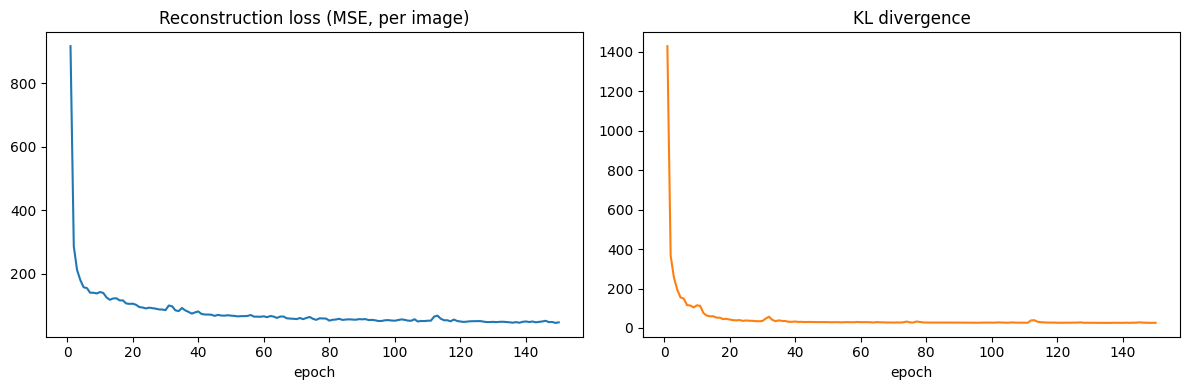

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history['epoch'], history['recon']); ax[0].set_title('Reconstruction loss (MSE, per image)')
ax[1].plot(history['epoch'], history['kl'], color='C1'); ax[1].set_title('KL divergence')
for a in ax: a.set_xlabel('epoch')
plt.tight_layout(); plt.savefig(f'{PROJECT}/results/cvae_losses.png', dpi=150); plt.show()

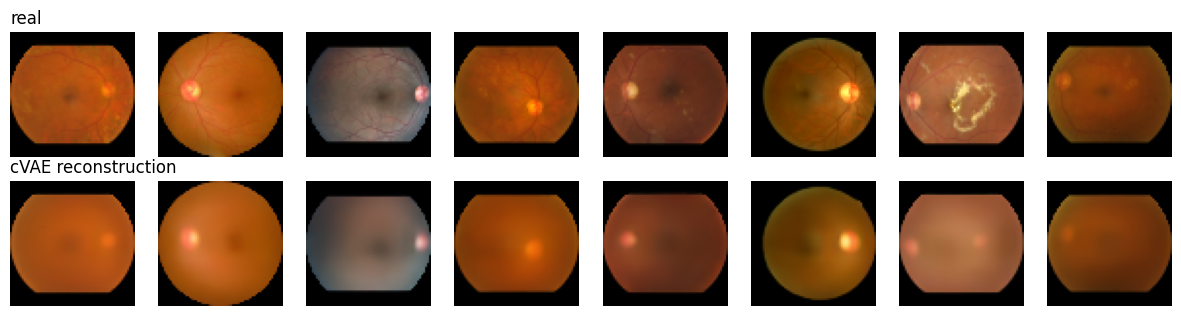

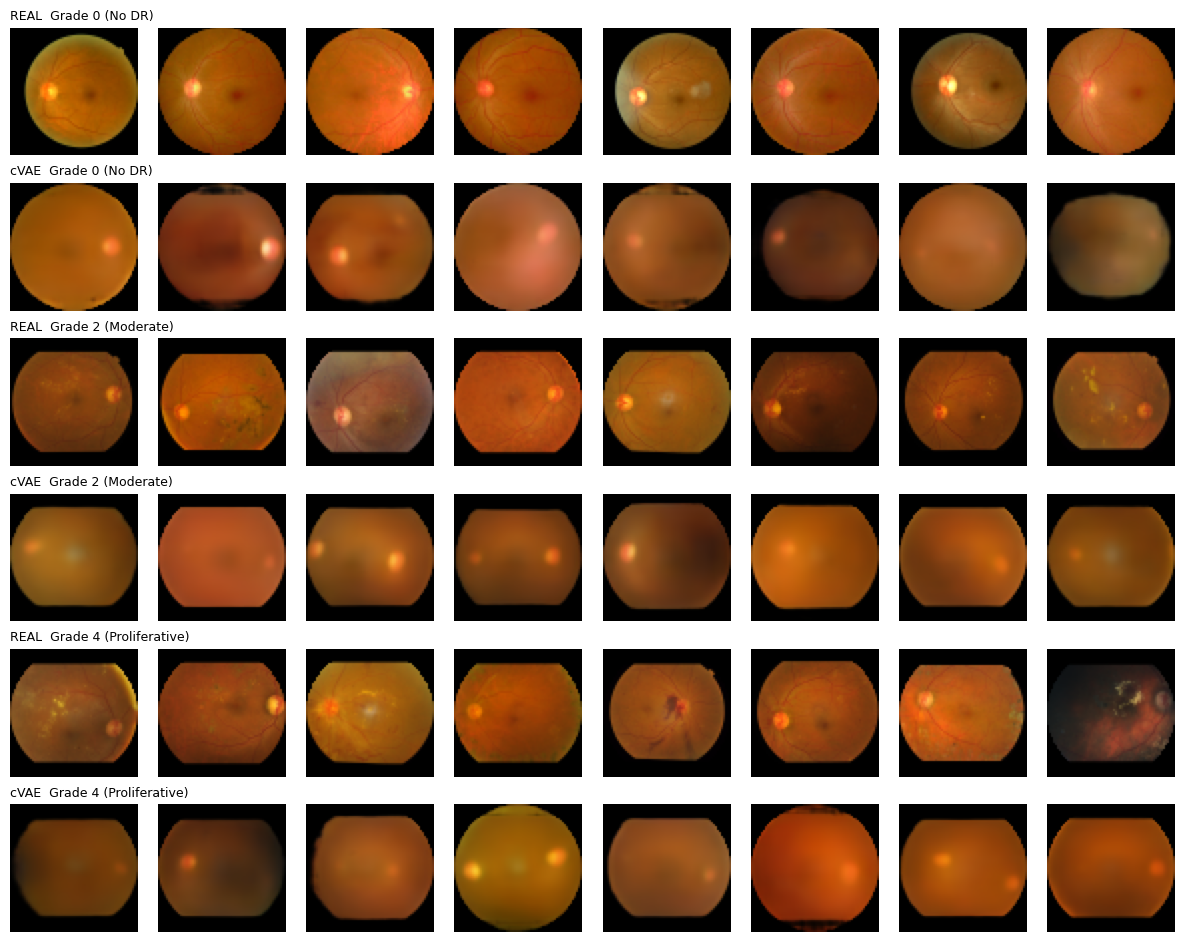

In [3]:
# load the trained weights (so this works after a runtime restart, without re-training)
vae.load_state_dict(torch.load(f'{PROJECT}/checkpoints/cvae_final.pt', map_location=device))
vae.eval()
to_img = lambda t: ((t * 0.5 + 0.5).clamp(0, 1) * CIRCLE).permute(1, 2, 0).cpu()   # black corners

# (a) reconstructions: top = real, bottom = reconstruction
with torch.no_grad():
    ids = torch.arange(0, len(X_t), len(X_t) // 8)[:8].to(device)
    rec, _, _ = vae(X_t[ids], Y_t[ids])
fig, axes = plt.subplots(2, 8, figsize=(12, 3.2))
for j in range(8):
    axes[0, j].imshow(to_img(X_t[ids[j]])); axes[1, j].imshow(to_img(rec[j]))
    axes[0, j].axis('off'); axes[1, j].axis('off')
axes[0, 0].set_title('real', loc='left'); axes[1, 0].set_title('cVAE reconstruction', loc='left')
plt.tight_layout(); plt.savefig(f'{PROJECT}/results/cvae_reconstructions.png', dpi=150); plt.show()

# (b) new samples from the prior, per grade
rng = np.random.default_rng(1)
fig, axes = plt.subplots(6, 8, figsize=(12, 9.5))
with torch.no_grad():
    for k in range(NUM_CLASSES):
        real_ids = rng.choice(np.where(Y == k)[0], 8, replace=False)
        fake = vae.decode(torch.randn(8, Z_DIM, device=device), torch.full((8,), k, device=device))
        for j in range(8):
            axes[2 * k, j].imshow(X[real_ids[j]]); axes[2 * k + 1, j].imshow(to_img(fake[j]))
            axes[2 * k, j].axis('off'); axes[2 * k + 1, j].axis('off')
        axes[2 * k, 0].set_title(f'REAL  {CLASS_NAMES[k]}', loc='left', fontsize=9)
        axes[2 * k + 1, 0].set_title(f'cVAE  {CLASS_NAMES[k]}', loc='left', fontsize=9)
plt.tight_layout(); plt.savefig(f'{PROJECT}/results/cvae_real_vs_fake.png', dpi=150); plt.show()

In [4]:
@torch.no_grad()
def generate(n_per_class, seed, batch=250):
    g = torch.Generator(device=device).manual_seed(seed)
    imgs, labs = [], []
    for k in range(NUM_CLASSES):
        for s in range(0, n_per_class, batch):
            n = min(batch, n_per_class - s)
            z = torch.randn(n, Z_DIM, device=device, generator=g)
            x = (vae.decode(z, torch.full((n,), k, device=device)) * 0.5 + 0.5).clamp(0, 1) * CIRCLE
            x = (x * 255).round().byte()                    # black outside the FOV, like real
            imgs.append(x.permute(0, 2, 3, 1).cpu().numpy()); labs.append(np.full(n, k))
    return np.concatenate(imgs), np.concatenate(labs)

vae.eval()
for seed in [0, 1, 2]:
    xs, ys = generate(1000, seed)
    np.savez_compressed(f'{PROJECT}/synthetic/cvae_seed{seed}.npz', images=xs, labels=ys)
    print('seed', seed, xs.shape, np.bincount(ys))
print(sorted(os.listdir(f'{PROJECT}/synthetic')))

seed 0 (3000, 64, 64, 3) [1000 1000 1000]
seed 1 (3000, 64, 64, 3) [1000 1000 1000]
seed 2 (3000, 64, 64, 3) [1000 1000 1000]
['cgan_seed0.npz', 'cgan_seed1.npz', 'cgan_seed2.npz', 'cvae_seed0.npz', 'cvae_seed1.npz', 'cvae_seed2.npz']
